In [2]:
import pyreadr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pyreadr.read_r("../data/lingBinary.Rdata")
df = next(iter(data.values()))

In [3]:
df.shape

(45152, 474)

In [4]:
df.head()

,ID,CITY,STATE,ZIP,lat,long,Q050_1,Q050_2,Q050_3,Q050_4,...,Q120_4,Q120_5,Q120_6,Q121_1,Q121_2,Q121_3,Q121_4,Q121_5,Q121_6,Q121_7
0,1,Boise,ID,83704,43.631230,-116.287161,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,2,Pittsfield,MA,1201,42.453840,-73.254003,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,3,Burlington,VT,5401,44.484038,-73.221265,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,Easton,PA,18042,40.681798,-75.220820,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,Bedford,MA,1730,42.496679,-71.275046,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
# select binary variables
X = df.iloc[:, 6:].to_numpy()

In [6]:
X.shape

(45152, 468)

In [7]:
# missing values?

In [8]:
np.isnan(X).sum()

np.int64(0)

In [ ]:
# Similarity implementation... on similarity.py


In [10]:
from similarity import similarity

similarity([0, 0, 1, 1], [1, 1, 0, 0])

np.float64(1.0)

In [11]:
# speed measure

a = np.random.randint(0, 10, 29000)
b = np.random.randint(0, 10, 29000)

%timeit similarity(a, b)

5.52 ms ± 127 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [13]:
# 5.52 ms ± 127 μs per loop ... to make it faster, I've made new similarity.py
# with using np.bincount function instead of using for~

In [14]:
import importlib
import similarity

importlib.reload(similarity)

<module 'similarity' from '/Users/miniwondeok/Desktop/215a/stat-215a/lab3/code/similarity.py'>

In [17]:
# measure the speed again

similarity.similarity([0, 0, 1, 1], [1, 1, 0, 0])

np.float64(1.0)

In [18]:
%timeit similarity.similarity(a, b)

1.48 ms ± 214 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [19]:
m = 0.2
n = len(X)

rng = np.random.default_rng(100)

idx1 = rng.choice(n, int(n * m), replace=False)
idx2 = rng.choice(n, int(n * m), replace=False)

sub1 = X[idx1]
sub2 = X[idx2]

In [20]:
sub1.shape, sub2.shape

((9030, 468), (9030, 468))

In [21]:
from sklearn.cluster import KMeans

k = 3

labels1 = KMeans(n_clusters=k, random_state=100).fit_predict(sub1)
labels2 = KMeans(n_clusters=k, random_state=100).fit_predict(sub2)

In [22]:
common, i1, i2 = np.intersect1d(idx1, idx2, return_indices=True)

len(common)

1808

In [23]:
similarity.similarity(labels1[i1], labels2[i2])

np.float64(0.9396496719436586)

In [24]:
from parallel_kmeans import run_once

run_once(X, k=3, m=0.2, seed=100)

np.float64(0.9396496719436586)

In [25]:
import importlib
import parallel_kmeans

importlib.reload(parallel_kmeans)

<module 'parallel_kmeans' from '/Users/miniwondeok/Desktop/215a/stat-215a/lab3/code/parallel_kmeans.py'>

In [26]:
test = parallel_kmeans.run_parallel(X, m=0.2, B=2, n_jobs=2)
test.shape

(2, 9)

In [27]:
%time test = parallel_kmeans.run_parallel(X, m=0.8, B=1, n_jobs=4)

CPU times: user 25.6 ms, sys: 69.5 ms, total: 95.1 ms
Wall time: 6.67 s


In [28]:
%time S = parallel_kmeans.run_parallel(X, m=0.8, B=100, n_jobs=4)

CPU times: user 1.04 s, sys: 506 ms, total: 1.55 s
Wall time: 6min 33s


In [29]:
from pathlib import Path

Path("../results").mkdir(exist_ok=True)

pd.DataFrame(S, columns=range(2, 11)).to_csv(
    "../results/S.csv", index=False
)

In [30]:
S.shape

(100, 9)

In [31]:
pd.DataFrame(S, columns=range(2, 11)).describe()

,2,3,4,5,6,7,8,9,10
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.736480,0.955970,0.711249,0.649303,0.518781,0.417359,0.396960,0.380451,0.365759
std,0.196497,0.028432,0.179795,0.155760,0.126187,0.107188,0.093395,0.079271,0.065804
min,0.345905,0.900030,0.413201,0.361998,0.331325,0.294049,0.262660,0.248520,0.240269
25%,0.586429,0.927218,0.504543,0.523800,0.430966,0.338699,0.342584,0.327122,0.321705
50%,0.658200,0.969258,0.777036,0.641881,0.490905,0.382262,0.377489,0.362137,0.358038
75%,0.942883,0.982412,0.863316,0.781772,0.568136,0.476717,0.436209,0.420118,0.397919
max,0.994273,0.989822,0.973564,0.937762,0.961982,0.811419,0.788653,0.603631,0.641006


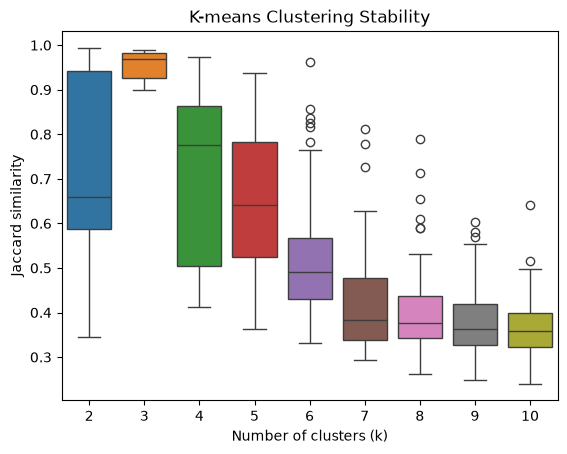

In [32]:
import seaborn as sns

results = pd.DataFrame(S, columns=range(2, 11))

sns.boxplot(data=results)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Jaccard similarity")
plt.title("K-means Clustering Stability")
plt.show()

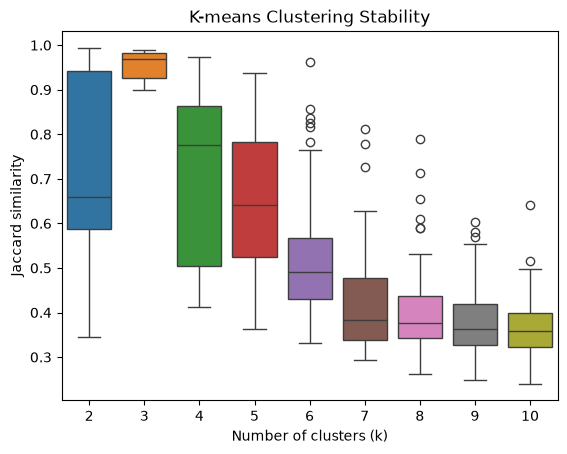

In [33]:
from pathlib import Path

Path("../figs").mkdir(exist_ok=True)

sns.boxplot(data=results)
plt.xlabel("Number of clusters (k)")
plt.ylabel("Jaccard similarity")
plt.title("K-means Clustering Stability")
plt.savefig("../figs/stability_plot.png", dpi=300, bbox_inches="tight")
plt.show()